In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import helper as hlp

### Plot enhancement as a function of etching round

In [2]:
''' LOAD THE ENHANCEMENT DATA '''
etch_round_data = hlp.load_enhancement_data()

# Optional: ignore the failed third round of etching.
ignore_failed = 1
if ignore_failed:
    # Indexing of etch_round_data (copied from helper.py):
    #        1st round -> 2nd round -> failed 3rd round -> 3rd round
    # Index: 0         -> 1         -> 2                -> 3
    indices_to_keep = np.array([0,1,3]) # First, second, and third (successful) etch rounds.
    etch_round_data_plotting = hlp.select_data(etch_round_data, indices_to_keep)
else:
    etch_round_data_plotting = etch_round_data

Loading file "1st Round of Etching.npy".
Loading file "2nd Round of Etching.npy".
Loading file "Failed 3rd Round of Etching.npy".
Loading file "3rd Round of Etching.npy".

Keeping the following data:
	"1st Round of Etching"
	"2nd Round of Etching"
	"3rd Round of Etching"


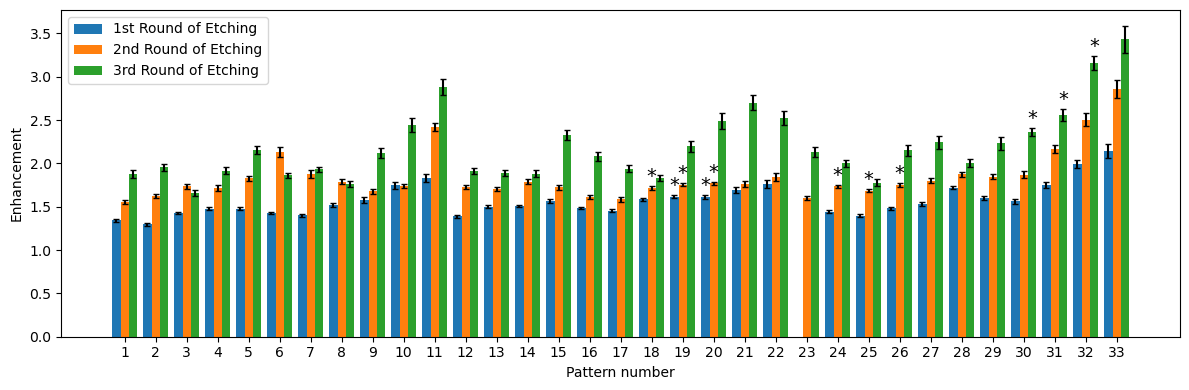

In [3]:
''' BAR PLOT AS A FUNCTION OF ETCH ROUND '''

# Create figure.
fig, ax = plt.subplots(figsize=(12, 4))

# Set up a grouped bar plot.
number_of_rounds = len(etch_round_data) - ignore_failed
indices = np.arange(33) # x-position for each pattern (1 to 33).
bar_width = 0.8/number_of_rounds # Total group width is 0.8.

# Loop through the datasets.
for i, etch_round in enumerate(etch_round_data_plotting):
    # Make the failed etching round have translucent bars.
    transparency = 1.0
    if 'Failed' in etch_round['label']:
        transparency = 0.3
    
    # Compute x-positions for bars in this etch round group.
    position = indices - 0.4 + (i + 0.5)*bar_width
    bars = ax.bar(position, etch_round['enhancement'], bar_width, yerr=etch_round['error'], label=etch_round['label'],
                  capsize=2, alpha=transparency)
    
    # Mark averaged measurements (flagged points) by adding an asterisk above the bar.
    for j, bar in enumerate(bars):
        if etch_round['flag'][j]:
            height = bar.get_height()
            if not np.isnan(height):
                ax.text(bar.get_x() + bar.get_width()/2., height + etch_round['error'][j], '*',
                        ha='center', va='bottom', color='black', fontsize=14)

ax.set_xlabel('Pattern number')
ax.set_ylabel('Enhancement')
ax.set_xticks(indices)
ax.set_xticklabels(np.arange(1, 33+1))
ax.legend()
plt.tight_layout()
plt.show()

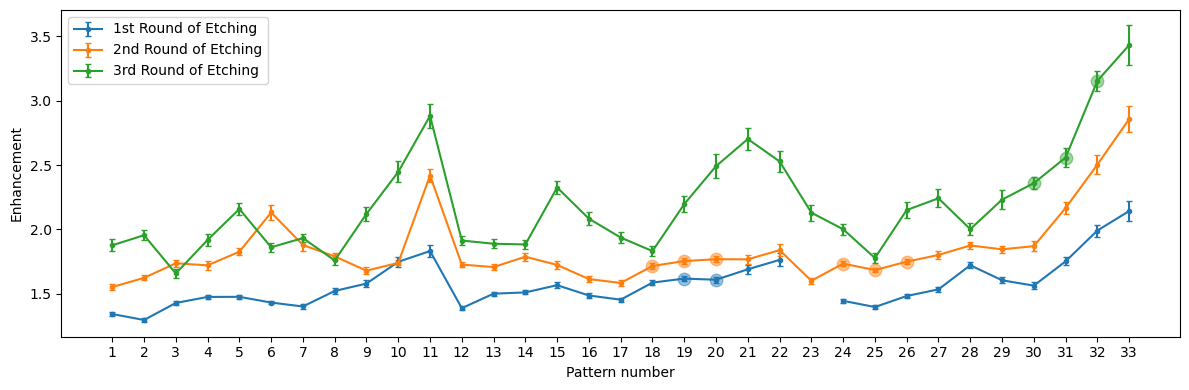

In [4]:
''' LINE PLOT AS A FUNCTION OF ETCH ROUND '''

# Create figure.
fig, ax = plt.subplots(figsize=(12, 4))

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

# Loop through the datasets.
for i, etch_round in enumerate(etch_round_data_plotting):
    # Make the failed etching round have a different line style.
    line_style = '.-'
    line_width = 1.5
    transparency = 0.45
    if 'Failed' in etch_round['label']:
        line_style = '.--'
        line_width = 0.75
        transparency = 0.15
    
    plt.errorbar(etch_round['pattern_numbers'], etch_round['enhancement'], yerr=etch_round['error'],
                 fmt=line_style, linewidth=line_width, color=colors[i], label=etch_round['label'], capsize=2)
    
    # Overlay the averaged points with a distinct, translucent marker.
    flagged_indices = etch_round['flag'] == 1.
    plt.plot(etch_round['pattern_numbers'][flagged_indices], etch_round['enhancement'][flagged_indices],
             'o', color=colors[i], markersize=9, alpha=transparency)

ax.set_xlabel('Pattern number')
ax.set_ylabel('Enhancement')
ax.set_xticks(etch_round['pattern_numbers']) # Use the pattern numbers from the last loop iteration. They're all the same.
ax.legend()
plt.tight_layout()
plt.show()

### Plot estimated etch length as a function of etch round

In [5]:
''' LOAD LENGTH DATA '''
etch_round_data, parameters = hlp.load_length_data()

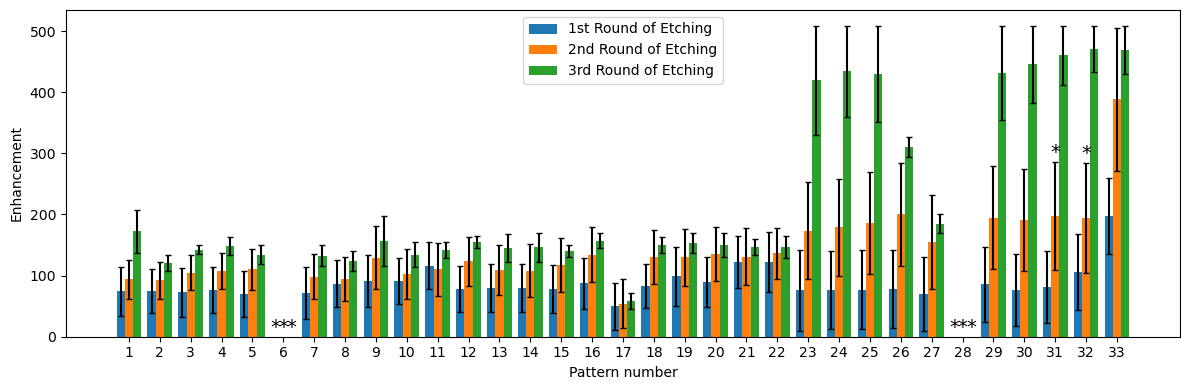

In [6]:
''' BAR PLOT AS A FUNCTION OF ETCH ROUND '''

# Create figure.
fig, ax = plt.subplots(figsize=(12, 4))

# Set up a grouped bar plot.
number_of_rounds = 3
indices = np.arange(33) # x-position for each pattern (1 to 33).
bar_width = 0.8/number_of_rounds # Total group width is 0.8.

# Loop through the datasets.
for i, etch_round in enumerate(etch_round_data):
    # Compute x-positions for bars in this etch round group.
    position = indices - 0.4 + (i + 0.5)*bar_width
    bars = ax.bar(position, etch_round['length'], bar_width, yerr=etch_round['error'],
                  label=etch_round['label'], capsize=2)
    
    # Mark flagged measurements by adding an asterisk above the bar.
    for j, bar in enumerate(bars):
        if etch_round['flag'][j]:
            height = bar.get_height()
            if not np.isnan(height):
                ax.text(bar.get_x() + bar.get_width()/2., height + etch_round['error'][j], '*',
                        ha='center', va='bottom', color='black', fontsize=14)
            else: # Some of the values are nan, so just put the asterisk above 0.0.
                ax.text(bar.get_x() + bar.get_width()/2., 0.0, '*',
                        ha='center', va='bottom', color='black', fontsize=14)

ax.set_xlabel('Pattern number')
ax.set_ylabel('Enhancement')
ax.set_xticks(indices)
ax.set_xticklabels(np.arange(1, 33+1))
ax.legend()
plt.tight_layout()
plt.show()

meta NOT subset; don't know how to subset; dropped


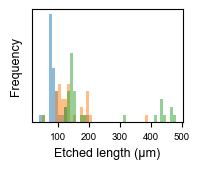

In [69]:
''' HISTOGRAM OF ETCH LENGTHS '''

# For embedding fonts.
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'

# Set up the figure size.
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(2.1, 1.8))

# Set up the bins.
bin_size = 10
bins = np.arange(40,480+bin_size,bin_size)

# Loop through etch rounds and plot a histogram for each.
for i, etch_round in enumerate(etch_round_data):
    axes.hist(etch_round['length'], bins=bins, linewidth=0, alpha=0.5, label=f'{i+1}')
    axes.set_xlabel('Etched length (μm)', fontsize=9)
    axes.set_ylabel('Frequency', fontsize=9)

# Adjust ticks and font size.
axes.set_xticks([100, 200, 300, 400, 500])
axes.set_yticks([])
axes.tick_params(axis='both', which='major', labelsize=7)
axes.tick_params(axis='y', labelleft=False)

plt.tight_layout()

# Save the figure as a PDF with embedded fonts.
fig.savefig('etch_histogram.pdf', format='pdf')
plt.show()